# 06 · Warehouse marts and KPIs with dbt: BankSight

**What this notebook does, in one paragraph:** it builds clean, tested KPI tables inside our DuckDB warehouse using **dbt** (a tool that turns SQL files into
tables and checks them with data tests), then reads those tables, draws the monthly trend, and double-checks one number against an independent calculation.

**Layers (the standard dbt pattern)**
| layer | what it holds | our models |
|---|---|---|
| raw (source) | data exactly as loaded | `raw.cfpb_complaints`, `features.complaint_labels` |
| staging | one tidy row per complaint | `stg_complaints` |
| intermediate | complaint + label + split | `int_complaints_labeled` |
| marts | KPI tables for dashboards | `mart_monthly_kpis`, `mart_product_kpis`, `mart_issue_kpis` |

**What this does:** loads the libraries. We will run dbt as a separate small program (with `subprocess`), exactly as if typed in a terminal,
so it releases the database file as soon as it finishes.

In [1]:
import subprocess
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

**What this does:** sets the file locations and stops with a clear message if the dbt files have not been created yet.

In [2]:
ROOT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
WAREHOUSE = ROOT / "data" / "warehouse" / "banksight.duckdb"
DBT_DIR = ROOT / "dbt_banksight"
KPI_DIR = ROOT / "reports" / "kpis"
KPI_DIR.mkdir(parents=True, exist_ok=True)

assert WAREHOUSE.exists(), "Run notebooks 01 and 01b first."
assert (DBT_DIR / "dbt_project.yml").exists(), "Run  python make_dbt_project.py  from the banksight folder first."
print("warehouse:", WAREHOUSE.resolve())
print("dbt project:", DBT_DIR.resolve())

warehouse: D:\Resume\Data Scientist\Resume_Projects\BankSight_Consumer Complaint Intelligence Platform\data\warehouse\banksight.duckdb
dbt project: D:\Resume\Data Scientist\Resume_Projects\BankSight_Consumer Complaint Intelligence Platform\dbt_banksight


**What this does:** the same dates we froze in notebook 01b, used later to mark the train / validation / test periods on the chart.

In [3]:
VAL_START = "2025-07-01"
TEST_START = "2025-11-01"

## 1. Build the tables with dbt
Three commands, always in this order: **seed** (load the small mapping table), **run** (build the models), **test** (check the data).

**What this does:** sets up how we call dbt (using the same Python that runs this notebook, so no PATH problems), then loads the seed file
`product_group_map.csv`, which maps each product group to a product family (for example "Mortgage" belongs to "Lending").

In [4]:
dbt_command = [sys.executable, "-W", "ignore", "-m", "dbt.cli.main"]
dbt_args = ["--project-dir", str(DBT_DIR.resolve()), "--profiles-dir", str(DBT_DIR.resolve())]

seed_result = subprocess.run(dbt_command + ["seed"] + dbt_args, capture_output=True, text=True)
print(*seed_result.stdout.splitlines()[-6:], sep="\n")
print("seed succeeded:", seed_result.returncode == 0)

09:54:53  
09:54:53  Finished running 1 seed in 0 hours 0 minutes and 0.59 seconds (0.59s).
09:54:53  
09:54:53  Completed successfully
09:54:53  
09:54:53  Done. PASS=1 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=1
seed succeeded: True


**What this does:** builds the five models. Staging and intermediate are views (saved queries). The three marts are real tables.

In [5]:
run_result = subprocess.run(dbt_command + ["run"] + dbt_args, capture_output=True, text=True)
print(*run_result.stdout.splitlines()[-8:], sep="\n")
print("run succeeded:", run_result.returncode == 0)

09:55:10  5 of 5 START sql table model analytics.mart_product_kpis ....................... [RUN]
09:55:10  5 of 5 OK created sql table model analytics.mart_product_kpis .................. [OK in 0.15s]
09:55:10  
09:55:10  Finished running 3 table models, 2 view models in 0 hours 0 minutes and 1.20 seconds (1.20s).
09:55:10  
09:55:10  Completed successfully
09:55:10  
09:55:10  Done. PASS=5 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=5
run succeeded: True


**What this does:** runs the 13 data tests: unique and not-null ids, valid split names, every product group present in the mapping,
rates between 0 and 1, and a reconciliation that the monthly table adds up to the base table. If any test fails, read its name:
it says exactly what is wrong.

In [6]:
test_result = subprocess.run(dbt_command + ["test"] + dbt_args, capture_output=True, text=True)
print(*test_result.stdout.splitlines()[-20:], sep="\n")
print("tests passed:", test_result.returncode == 0)
assert test_result.returncode == 0, "A dbt test failed. Read the test name above to see which check broke."

09:55:28  7 of 13 START test not_null_stg_complaints_complaint_id ........................ [RUN]
09:55:28  7 of 13 PASS not_null_stg_complaints_complaint_id .............................. [PASS in 0.03s]
09:55:28  8 of 13 START test not_null_stg_complaints_product_group ....................... [RUN]
09:55:28  8 of 13 PASS not_null_stg_complaints_product_group ............................. [PASS in 0.03s]
09:55:28  9 of 13 START test relationships_int_complaints_labeled_product_group__product_group__ref_product_group_map_  [RUN]
09:55:28  9 of 13 PASS relationships_int_complaints_labeled_product_group__product_group__ref_product_group_map_  [PASS in 0.12s]
09:55:28  10 of 13 START test unique_int_complaints_labeled_complaint_id ................. [RUN]
09:55:29  10 of 13 PASS unique_int_complaints_labeled_complaint_id ....................... [PASS in 0.10s]
09:55:29  11 of 13 START test unique_mart_monthly_kpis_month ............................. [RUN]
09:55:29  11 of 13 PASS unique_mart

## 2. Read the KPI tables

**What this does:** opens the warehouse (read-only) and loads the monthly KPI table into a pandas table.

In [7]:
con = duckdb.connect(str(WAREHOUSE), read_only=True)
monthly = con.sql("SELECT * FROM analytics.mart_monthly_kpis ORDER BY month").df()
monthly["month"] = pd.to_datetime(monthly["month"])
display(monthly)

,month,split,complaints,eligible_complaints,relief_cases,monetary_relief_cases,untimely_cases,relief_rate,monetary_share_of_relief,untimely_rate,relief_rate_3m,relief_rate_change_vs_prev_month
0,2023-01-01,train,2576,2573.0,478.0,193.0,33.0,0.1858,0.4038,0.0128,0.1858,NaN
1,2023-02-01,train,2035,2033.0,420.0,166.0,28.0,0.2066,0.3952,0.0138,0.1950,0.0208
2,2023-03-01,train,2346,2342.0,503.0,195.0,30.0,0.2148,0.3877,0.0128,0.2016,0.0082
3,2023-04-01,train,1941,1939.0,414.0,152.0,30.0,0.2135,0.3671,0.0155,0.2118,-0.0013
4,2023-05-01,train,2191,2188.0,505.0,141.0,29.0,0.2308,0.2792,0.0132,0.2198,0.0173
5,2023-06-01,train,2214,2212.0,566.0,154.0,14.0,0.2559,0.2721,0.0063,0.2343,0.0251
6,2023-07-01,train,2279,2271.0,605.0,181.0,19.0,0.2664,0.2992,0.0083,0.2512,0.0105
7,2023-08-01,train,2557,2555.0,674.0,173.0,33.0,0.2638,0.2567,0.0129,0.2621,-0.0026
8,2023-09-01,train,2435,2431.0,616.0,173.0,60.0,0.2534,0.2808,0.0246,0.2611,-0.0104
9,2023-10-01,train,2686,2685.0,680.0,191.0,55.0,0.2533,0.2809,0.0205,0.2568,-0.0001


**What this does:** loads the product table. Note its rule: only train and validation rows are used, so the sealed test period is never shown by product.

In [8]:
products = con.sql("SELECT * FROM analytics.mart_product_kpis ORDER BY complaints DESC").df()
display(products)

,product_family,product_group,complaints,eligible_complaints,relief_cases,relief_rate,monetary_share_of_relief,untimely_rate
0,Credit and reporting,Credit reporting,23642,23630.0,11257.0,0.4764,0.0021,0.0020
1,Credit and reporting,Credit or prepaid card,19858,19845.0,6697.0,0.3375,0.4778,0.0086
2,Banking and payments,Bank account,19548,19536.0,3561.0,0.1823,0.6827,0.0078
3,Collections and debt,Debt collection,19544,19432.0,4972.0,0.2559,0.0151,0.0227
4,Banking and payments,Money transfer / virtual currency,17465,17448.0,945.0,0.0542,0.6275,0.0111
5,Lending,Mortgage,7924,7899.0,373.0,0.0472,0.4638,0.0115
6,Lending,Vehicle loan or lease,5353,5321.0,434.0,0.0816,0.3249,0.0163
7,Lending,Student loan,5235,4915.0,213.0,0.0433,0.2441,0.1706
8,Lending,Payday / personal loan,3465,3425.0,262.0,0.0765,0.5611,0.0444
9,Collections and debt,Debt or credit management,898,863.0,108.0,0.1251,0.2315,0.0913


**What this does:** shows the three largest issues inside each product group, with their relief rates.

In [9]:
top_issues = con.sql("SELECT * FROM analytics.mart_issue_kpis WHERE rank_in_product <= 3 ORDER BY product_group, rank_in_product").df()
display(top_issues)

,product_group,issue,complaints,eligible_complaints,relief_cases,relief_rate,rank_in_product
0,Bank account,Managing an account,10363,10355.0,1932.0,0.1866,1
1,Bank account,Closing an account,2733,2733.0,510.0,0.1866,2
2,Bank account,Problem caused by your funds being low,2544,2543.0,334.0,0.1313,3
3,Credit or prepaid card,Problem with a purchase shown on your statement,4305,4303.0,1542.0,0.3584,1
4,Credit or prepaid card,Getting a credit card,2088,2085.0,723.0,0.3468,2
5,Credit or prepaid card,"Other features, terms, or problems",2052,2051.0,559.0,0.2725,3
6,Credit reporting,Incorrect information on your report,11244,11238.0,5494.0,0.4889,1
7,Credit reporting,Improper use of your report,6835,6831.0,3197.0,0.4680,2
8,Credit reporting,Problem with a company's investigation into an...,4300,4299.0,2080.0,0.4838,3
9,Debt collection,Attempts to collect debt not owed,9033,8991.0,2265.0,0.2519,1


## 3. Chart the monthly relief rate

**What this does:** draws the monthly relief rate (thin line) and its 3-month rolling average (thick line). The dashed lines mark where the
validation and test periods start.

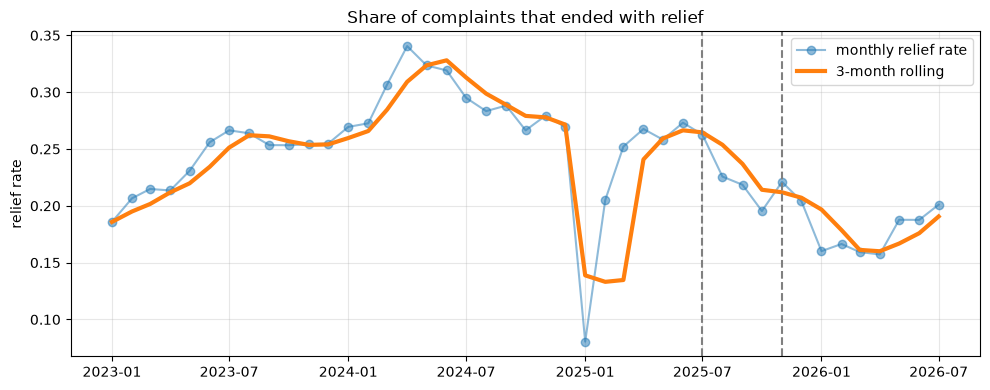

In [10]:
plt.figure(figsize=(10, 4))
plt.plot(monthly["month"], monthly["relief_rate"], "o-", alpha=0.5, label="monthly relief rate")
plt.plot(monthly["month"], monthly["relief_rate_3m"], "-", linewidth=3, label="3-month rolling")
plt.axvline(pd.Timestamp(VAL_START), color="grey", linestyle="--")
plt.axvline(pd.Timestamp(TEST_START), color="grey", linestyle="--")
plt.title("Share of complaints that ended with relief")
plt.ylabel("relief rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(ROOT / "reports" / "figures" / "06_monthly_relief_rate.png", dpi=140)
plt.show()

## 4. Check one number independently
A dashboard number is only trustworthy if it can be reproduced another way. We compute the overall relief rate straight from the labels table
(no dbt) and compare it with the rate implied by the monthly mart.

**What this does:** calculates the overall relief rate directly from the labels table.

In [11]:
labels = con.sql("SELECT got_relief FROM features.complaint_labels WHERE target_eligible").df()
rate_direct = labels["got_relief"].mean()
print("direct from labels table:", round(rate_direct, 6))

direct from labels table: 0.226342


**What this does:** calculates the same rate from the dbt monthly table and checks the two agree.

In [12]:
rate_from_mart = monthly["relief_cases"].sum() / monthly["eligible_complaints"].sum()
print("from dbt monthly mart:   ", round(rate_from_mart, 6))
assert abs(rate_direct - rate_from_mart) < 1e-9, "The dbt mart does not reproduce the direct calculation!"
print("match: the dbt mart reproduces the direct calculation")

from dbt monthly mart:    0.226342
match: the dbt mart reproduces the direct calculation


## 5. Save the KPI tables
These CSV files are what the dashboard (a later step) will read.

**What this does:** saves the three KPI tables as CSV files and closes the database.

In [13]:
monthly.to_csv(KPI_DIR / "monthly_kpis.csv", index=False)
products.to_csv(KPI_DIR / "product_kpis.csv", index=False)
top_issues.to_csv(KPI_DIR / "top_issues_per_product.csv", index=False)
con.close()
print("saved:", *sorted(p.name for p in KPI_DIR.glob("*.csv")), sep="\n  ")

saved:
  monthly_kpis.csv
  product_kpis.csv
  top_issues_per_product.csv


## How to explain this in an interview
> "I modelled the warehouse in layers with dbt: staging, an intermediate table that joins labels, and marts for KPIs. Every KPI has one written definition in a
> KPI dictionary, 13 automated data tests guard it, and I reconcile the monthly mart against an independent calculation. The same SQL can later run on
> Snowflake by changing one profile. I also deliberately kept the sealed test period out of the product and issue marts."